# 07 - Quantum Circuit Design for the 8-D Iris Embedding

## Objective

Notebook 6 compressed the iris embedding to **8 dimensions** with a classical
projection head (test AUC 0.8747, EER 0.2218). This notebook designs and
selects the **variational quantum circuit (VQC)** that will replace / follow
that head in Notebook 8.

The circuit is an **8-qubit** model:

```
8-D embedding x  ──►  angle encoding  ──►  [ rotations → entanglers ] × L  ──►  ⟨Z⟩ on each qubit  ──►  8-D quantum embedding
```

It is simulated **exactly** (noiseless state-vector) with a small
differentiable PyTorch simulator written for this project, so no quantum
library is required.

## Why a separate circuit-design notebook?

Training the CNN, the projection head and the circuit together is slow and
makes it impossible to tell *what* helped. Here the CNN is frozen: the
cached 8-D embeddings from Notebook 6 are used, so each circuit trains in
seconds and many designs can be compared fairly.

## Design questions answered

1. **Depth** - how many variational layers?
2. **Rotation gates** - RY only, RY+RZ, or RX+RY+RZ?
3. **Entanglement** - none / linear / ring / all-to-all, CNOT vs CZ?
4. **Encoding** - RY, RX, RY+RZ, or data re-uploading?
5. **Input scaling** - how to map embedding values to rotation angles?
6. **Trainability** - does depth cause vanishing gradients (barren plateaus)?
7. **Is the circuit better than a classical head with a similar number of parameters?**

## Experimental Protocol

- Identity-disjoint train / validation / test splits (Notebooks 3 and 6).
- **Same validation and test pairs as Notebooks 5 and 6.**
- Circuit design is selected on **validation** AUC only.
- Test is evaluated once, for the final model, with the validation threshold.
- The final comparison uses several random seeds, because single-seed
  differences of about 0.005 AUC are inside the noise (seen in Notebook 6).
- Controls: raw Notebook 6 embedding (no extra head), a classical linear
  8→8 head and a classical 8→16→8 MLP head.

## Outputs

1. `quantum_sim.py` - reusable circuit module (imported again in Notebook 8).
2. Ablation tables and plots for every design question.
3. Gradient-variance (trainability) analysis.
4. Best circuit configuration (`best_circuit_config.json`) and trained weights.
5. Multi-seed comparison: quantum vs classical heads vs Notebook 6.

## Important caveat

The circuit here is trained on **cached embeddings of the training images**
produced by an encoder that was itself trained on those images, and without
image augmentation. Notebook 8 repeats the final design end-to-end.

In [1]:
# ============================================================
# CELL 2: Import libraries
# ============================================================

import os
import sys
import json
import math
import copy
import time
import random
from pathlib import Path
from functools import reduce

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    roc_curve,
    roc_auc_score
)

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim


print("All libraries imported successfully.")
print("PyTorch:", torch.__version__)

All libraries imported successfully.
PyTorch: 2.14.1+cu126


In [2]:
# ============================================================
# CELL 3: Reproducibility
# ============================================================

SEED = 42


def set_seed(seed=SEED):

    random.seed(seed)

    np.random.seed(seed)

    torch.manual_seed(seed)

    torch.cuda.manual_seed_all(seed)


set_seed()


print(f"Random seed set to: {SEED}")

Random seed set to: 42


In [3]:
# ============================================================
# CELL 4: Configuration
# ============================================================


# ------------------------------------------------------------
# Input / output directories
# ------------------------------------------------------------

NB6_DIR = Path("../classical_projection_baseline")      # Notebook 6

OUTPUT_DIR = Path("../quantum_circuit_experiments")     # Notebook 7

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# Quick smoke test: tiny run to check everything works (~2 min).
# Set to False for the real experiment.
# ------------------------------------------------------------

QUICK_TEST = False


# ------------------------------------------------------------
# Circuit size
# ------------------------------------------------------------

N_QUBITS = 8                   # = dimension of the Notebook 6 embedding


# ------------------------------------------------------------
# Training configuration (on cached 8-D embeddings)
# ------------------------------------------------------------

LEARNING_RATE = 0.02

BATCH_PAIRS = 256              # pairs per step (512 embeddings)

PAIRS_PER_EPOCH = 12800        # fresh random pairs every epoch

EPOCHS_SWEEP = 15              # per design in the ablation sweeps

EPOCHS_FINAL = 40              # for the final multi-seed runs

PATIENCE = 8

CONTRASTIVE_MARGIN = 1.0

SWEEP_SEED = 0

FINAL_SEEDS = [0, 1, 2]


# ------------------------------------------------------------
# Gradient-variance analysis
# ------------------------------------------------------------

GRAD_DEPTHS = [1, 2, 3, 4, 6, 8, 12]

GRAD_INITS = 60


if QUICK_TEST:

    PAIRS_PER_EPOCH = 1280

    EPOCHS_SWEEP = 3

    EPOCHS_FINAL = 4

    PATIENCE = 3

    FINAL_SEEDS = [0, 1]

    GRAD_DEPTHS = [1, 2, 4]

    GRAD_INITS = 10


# ------------------------------------------------------------
# Simulator device
# ------------------------------------------------------------
# 8 qubits = 256 amplitudes: tiny, so CPU is usually as fast as GPU.
# Change to torch.device("cuda") to test the GPU.

SIM_DEVICE = torch.device("cpu")


print("Notebook 6 directory:", NB6_DIR)

print("Output directory:", OUTPUT_DIR)

print("Qubits:", N_QUBITS)

print("Simulator device:", SIM_DEVICE)

print("Quick test mode:", QUICK_TEST)

Notebook 6 directory: ..\classical_projection_baseline
Output directory: ..\quantum_circuit_experiments
Qubits: 8
Simulator device: cpu
Quick test mode: False


In [4]:
# ============================================================
# CELL 5: Verify Notebook 6 outputs
# ============================================================

required_files = [
    "train_embeddings.npz",
    "validation_embeddings.npz",
    "test_embeddings.npz",
    "validation_pairs.csv",
    "test_pairs.csv",
    "final_results.csv",
    "model_config.json",
]

for name in required_files:

    path = NB6_DIR / name

    print(f"{name:30s}", "FOUND" if path.exists() else "MISSING")

    if not path.exists():

        raise FileNotFoundError(
            f"{path} not found. Run Notebook 6 completely first."
        )

train_embeddings.npz           FOUND
validation_embeddings.npz      FOUND
test_embeddings.npz            FOUND
validation_pairs.csv           FOUND
test_pairs.csv                 FOUND
final_results.csv              FOUND
model_config.json              FOUND


## The circuit simulator

The simulator is written to a file (`quantum_sim.py`) so that Notebook 8 uses
**exactly the same code**.

**State.** `n` qubits = `2ⁿ` complex amplitudes (256 for 8 qubits). Qubit 0 is
the most significant bit.

**Encoding.** Starting from |00000000⟩, qubit *i* is rotated by the angle
`scale · xᵢ` (RY by default). With RY encoding a qubit's ⟨Z⟩ is `cos(scale·xᵢ)`.

**Variational layer.** Every qubit gets trainable rotations (RY / RZ / RX),
followed by an entangling pattern of CNOT (or CZ) gates:

- `none` - no entanglement (product circuit; control experiment)
- `linear` - (0,1), (1,2) … (6,7)
- `ring` - linear + (7,0)
- `all` - every pair

**Measurement.** ⟨Z⟩ on each qubit → 8 numbers in [-1, 1], optionally
L2-normalised like the classical embeddings of Notebooks 5-6.

**Efficiency.** Gates are applied with `einsum` on a `(batch, 2^q, 2, 2^(n-q-1))`
view of the state; a full entangling layer is a single index permutation.
The whole simulation is differentiable with ordinary PyTorch autograd.

In [5]:
# ============================================================
# CELL 6: Write the reusable circuit module (quantum_sim.py)
# ============================================================

QUANTUM_SIM_SOURCE = r'''
# quantum_sim.py
# Exact, differentiable state-vector simulator for variational quantum
# circuits used in the iris-recognition project (Notebooks 7 and 8).

import math

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F


VALID_ROTATIONS = ("RX", "RY", "RZ")

VALID_ENTANGLEMENTS = ("none", "linear", "ring", "all")

VALID_ENTANGLERS = ("CNOT", "CZ")


def rotation_matrix(name, theta):
    # 2x2 complex rotation matrix for every element of theta.
    # theta: tensor of any shape S  ->  returns tensor of shape S + (2, 2)

    half = theta / 2.0

    c = torch.cos(half)

    s = torch.sin(half)

    z = torch.zeros_like(c)

    if name == "RY":

        real = torch.stack(
            [torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2
        )

        imag = torch.zeros_like(real)

    elif name == "RX":

        real = torch.stack(
            [torch.stack([c, z], -1), torch.stack([z, c], -1)], -2
        )

        imag = torch.stack(
            [torch.stack([z, -s], -1), torch.stack([-s, z], -1)], -2
        )

    elif name == "RZ":

        real = torch.stack(
            [torch.stack([c, z], -1), torch.stack([z, c], -1)], -2
        )

        imag = torch.stack(
            [torch.stack([-s, z], -1), torch.stack([z, s], -1)], -2
        )

    else:

        raise ValueError(f"Unknown rotation: {name}")

    return torch.complex(real, imag)


def entangling_pairs(n_qubits, topology):

    if topology == "none":

        return []

    linear = [(i, i + 1) for i in range(n_qubits - 1)]

    if topology == "linear":

        return linear

    if topology == "ring":

        return linear + ([(n_qubits - 1, 0)] if n_qubits > 2 else [])

    if topology == "all":

        return [
            (i, j)
            for i in range(n_qubits)
            for j in range(i + 1, n_qubits)
        ]

    raise ValueError(f"Unknown entanglement topology: {topology}")


def cnot_permutation(n_qubits, control, target):

    # new_state[idx] = state[perm[idx]]   (CNOT is its own inverse)

    idx = np.arange(2 ** n_qubits)

    control_bit = (idx >> (n_qubits - 1 - control)) & 1

    return idx ^ (control_bit << (n_qubits - 1 - target))


def cz_sign(n_qubits, control, target):

    idx = np.arange(2 ** n_qubits)

    control_bit = (idx >> (n_qubits - 1 - control)) & 1

    target_bit = (idx >> (n_qubits - 1 - target)) & 1

    return 1 - 2 * (control_bit & target_bit)


class QuantumCircuitEmbedder(nn.Module):

    def __init__(
        self,
        n_qubits=8,
        n_layers=3,
        rotations=("RY", "RZ"),
        entanglement="ring",
        entangler="CNOT",
        encoding=("RY",),
        reupload=False,
        input_scale=math.pi,
        trainable_input_scale=False,
        normalize_output=True,
        init="small_normal",
        init_std=0.1
    ):

        super().__init__()

        rotations = tuple(rotations)

        encoding = tuple(encoding)

        for g in rotations + encoding:

            if g not in VALID_ROTATIONS:

                raise ValueError(f"Unknown rotation: {g}")

        if entanglement not in VALID_ENTANGLEMENTS:

            raise ValueError(f"Unknown entanglement: {entanglement}")

        if entangler not in VALID_ENTANGLERS:

            raise ValueError(f"Unknown entangler: {entangler}")

        self.n_qubits = n_qubits

        self.n_layers = n_layers

        self.rotations = rotations

        self.encoding = encoding

        self.reupload = reupload

        self.normalize_output = normalize_output

        self.entanglement = entanglement

        self.entangler = entangler

        # ---------------- trainable circuit parameters -------------

        shape = (n_layers, n_qubits, len(rotations))

        if init == "uniform":

            theta = torch.rand(shape) * 2 * math.pi

        else:

            theta = torch.randn(shape) * init_std

        self.theta = nn.Parameter(theta)

        scale = torch.full((n_qubits,), float(input_scale))

        if trainable_input_scale:

            self.input_scale = nn.Parameter(scale)

        else:

            self.register_buffer("input_scale", scale)

        # ---------------- fixed tensors ----------------------------

        dim = 2 ** n_qubits

        idx = np.arange(dim)

        bits = (idx[:, None] >> (n_qubits - 1 - np.arange(n_qubits))[None, :]) & 1

        self.register_buffer(
            "z_sign", torch.tensor(1.0 - 2.0 * bits, dtype=torch.float32)
        )

        pairs = entangling_pairs(n_qubits, entanglement)

        self.pairs = pairs

        self.has_entanglers = len(pairs) > 0

        perm = np.arange(dim)

        sign = np.ones(dim)

        for control, target in pairs:

            if entangler == "CNOT":

                perm = perm[cnot_permutation(n_qubits, control, target)]

            else:

                sign = sign * cz_sign(n_qubits, control, target)

        self.register_buffer("ent_perm", torch.tensor(perm, dtype=torch.long))

        self.register_buffer("ent_sign", torch.tensor(sign, dtype=torch.float32))

    # ------------------------------------------------------------

    def num_circuit_parameters(self):

        return sum(p.numel() for p in self.parameters())

    def _apply_gate(self, state, matrix, qubit):

        batch = state.shape[0]

        n = self.n_qubits

        view = state.reshape(batch, 2 ** qubit, 2, 2 ** (n - 1 - qubit))

        if matrix.dim() == 2:

            view = torch.einsum("ij,bajc->baic", matrix, view)

        else:

            view = torch.einsum("bij,bajc->baic", matrix, view)

        return view.reshape(batch, -1)

    def _encode(self, state, x):

        for qubit in range(self.n_qubits):

            angle = x[:, qubit] * self.input_scale[qubit]

            for gate in self.encoding:

                state = self._apply_gate(
                    state, rotation_matrix(gate, angle), qubit
                )

        return state

    def expectations(self, x):

        x = x.float()

        if x.shape[1] != self.n_qubits:

            raise ValueError(
                f"Expected {self.n_qubits} features, got {x.shape[1]}"
            )

        batch = x.shape[0]

        state = torch.zeros(
            batch, 2 ** self.n_qubits,
            dtype=torch.complex64, device=x.device
        )

        state[:, 0] = 1.0

        if not self.reupload:

            state = self._encode(state, x)

        for layer in range(self.n_layers):

            if self.reupload:

                state = self._encode(state, x)

            for qubit in range(self.n_qubits):

                matrix = rotation_matrix(
                    self.rotations[0], self.theta[layer, qubit, 0]
                )

                for k in range(1, len(self.rotations)):

                    matrix = rotation_matrix(
                        self.rotations[k], self.theta[layer, qubit, k]
                    ) @ matrix

                state = self._apply_gate(state, matrix, qubit)

            if self.has_entanglers:

                state = state[:, self.ent_perm] * self.ent_sign

        probabilities = state.real ** 2 + state.imag ** 2

        return probabilities @ self.z_sign

    def forward(self, x):

        expectation = self.expectations(x)

        if self.normalize_output:

            expectation = F.normalize(expectation, p=2, dim=1, eps=1e-6)

        return expectation


def describe_circuit(config, n_qubits=8):

    rotations = "+".join(config["rotations"])

    encoding = "+".join(config["encoding"])

    pairs = entangling_pairs(n_qubits, config["entanglement"])

    lines = []

    lines.append(f"Qubits        : {n_qubits}")

    lines.append(
        f"Encoding      : {encoding}(scale * x_i) on qubit i"
        f"   scale = {config['input_scale']:.4f}"
        f"{' (trainable)' if config['trainable_input_scale'] else ''}"
        f"{'   [re-uploaded every layer]' if config['reupload'] else ''}"
    )

    lines.append(
        f"Layers        : {config['n_layers']} x "
        f"[ {rotations}(theta) on every qubit -> "
        f"{config['entangler']} {config['entanglement']} ]"
    )

    lines.append(f"Entangling    : {pairs if pairs else 'none'}")

    lines.append("Measurement   : <Z> on every qubit -> 8-D embedding")

    count = config["n_layers"] * n_qubits * len(config["rotations"])

    count += n_qubits if config["trainable_input_scale"] else 0

    lines.append(f"Trainable     : {count} parameters")

    return "\n".join(lines)
'''

(OUTPUT_DIR / "quantum_sim.py").write_text(QUANTUM_SIM_SOURCE.strip() + "\n")

print("Written:", OUTPUT_DIR / "quantum_sim.py")

Written: ..\quantum_circuit_experiments\quantum_sim.py


In [6]:
# ============================================================
# CELL 7: Import the module and verify the simulator
# ============================================================
#
# The simulator is checked against (a) analytic results and
# (b) a brute-force dense-matrix simulation built with np.kron.

import importlib

sys.path.insert(0, str(OUTPUT_DIR.resolve()))

import quantum_sim

importlib.reload(quantum_sim)

from quantum_sim import (
    QuantumCircuitEmbedder,
    rotation_matrix,
    cnot_permutation,
    entangling_pairs,
    describe_circuit
)


# ------------------------------------------------------------
# Dense reference (slow, exact, independent implementation)
# ------------------------------------------------------------

def dense_rotation(name, t):

    c, s = np.cos(t / 2), np.sin(t / 2)

    if name == "RY":

        return np.array([[c, -s], [s, c]], dtype=complex)

    if name == "RX":

        return np.array([[c, -1j * s], [-1j * s, c]], dtype=complex)

    return np.array(
        [[np.exp(-1j * t / 2), 0], [0, np.exp(1j * t / 2)]], dtype=complex
    )


def dense_expectations(module, x_row):

    n = module.n_qubits

    I2 = np.eye(2)

    X = np.array([[0, 1], [1, 0]])

    Z = np.diag([1, -1])

    P0, P1 = np.diag([1, 0]), np.diag([0, 1])

    def op(U, q):

        mats = [I2] * n

        mats[q] = U

        return reduce(np.kron, mats)

    def controlled(c, t, U):

        m0 = [I2] * n

        m0[c] = P0

        m1 = [I2] * n

        m1[c] = P1

        m1[t] = U

        return reduce(np.kron, m0) + reduce(np.kron, m1)

    theta = module.theta.detach().cpu().numpy()

    scale = module.input_scale.detach().cpu().numpy()

    psi = np.zeros(2 ** n, dtype=complex)

    psi[0] = 1

    def encode(psi):

        for q in range(n):

            for g in module.encoding:

                psi = op(dense_rotation(g, x_row[q] * scale[q]), q) @ psi

        return psi

    if not module.reupload:

        psi = encode(psi)

    for layer in range(module.n_layers):

        if module.reupload:

            psi = encode(psi)

        for q in range(n):

            for k, g in enumerate(module.rotations):

                psi = op(dense_rotation(g, theta[layer, q, k]), q) @ psi

        for c, t in module.pairs:

            psi = controlled(c, t, X if module.entangler == "CNOT" else Z) @ psi

    return np.array(
        [np.real(psi.conj() @ op(Z, q) @ psi) for q in range(n)]
    )


# ------------------------------------------------------------
# Tests
# ------------------------------------------------------------

torch.manual_seed(0)

# 1. Product-state check:  <Z_i> = cos(scale * x_i)

m = QuantumCircuitEmbedder(
    n_qubits=4, n_layers=1, entanglement="none", normalize_output=False
)

m.theta.data.zero_()

x = torch.rand(5, 4) * 2 - 1

assert torch.allclose(
    m.expectations(x), torch.cos(math.pi * x), atol=1e-5
), "product-state check failed"

print("✓ Product-state check:  <Z> = cos(pi * x)")


# 2. CNOT truth table  |10> -> |11>

perm = cnot_permutation(2, 0, 1)

assert perm[3] == 2 and perm[2] == 3 and perm[0] == 0 and perm[1] == 1

print("✓ CNOT truth table")


# 3. Random circuits vs dense reference (all gate / entangler options)

worst = 0.0

num_tested = 0

for n in (3, 4):

    for topology in ("none", "linear", "ring", "all"):

        for entangler in ("CNOT", "CZ"):

            for rotations in (("RY",), ("RY", "RZ"), ("RX", "RY", "RZ")):

                for encoding, reupload in (
                    (("RY",), False),
                    (("RX",), False),
                    (("RY", "RZ"), False),
                    (("RY",), True),
                ):

                    m = QuantumCircuitEmbedder(
                        n_qubits=n, n_layers=2, rotations=rotations,
                        entanglement=topology, entangler=entangler,
                        encoding=encoding, reupload=reupload,
                        init="uniform", normalize_output=False
                    )

                    x = torch.rand(2, n) * 2 - 1

                    fast = m.expectations(x).detach().numpy()

                    slow = np.stack(
                        [dense_expectations(m, x[i].numpy()) for i in range(2)]
                    )

                    worst = max(worst, np.abs(fast - slow).max())

                    num_tested += 1

assert worst < 1e-4, f"simulator mismatch: {worst}"

print(f"✓ {num_tested} random circuits match the dense simulation "
      f"(max abs error {worst:.2e})")


# 4. Outputs bounded, gradients flow

m = QuantumCircuitEmbedder(n_qubits=8, n_layers=3, init="uniform")

x = torch.rand(16, 8) * 2 - 1

e = m.expectations(x)

assert e.abs().max() <= 1.0 + 1e-5

(m(x)[:, 0]).sum().backward()

assert m.theta.grad is not None and torch.isfinite(m.theta.grad).all()

print("✓ <Z> within [-1, 1];  gradients are finite")


print("\nSimulator verified.\n")

print(describe_circuit(
    dict(n_layers=3, rotations=("RY", "RZ"), entanglement="ring",
         entangler="CNOT", encoding=("RY",), reupload=False,
         input_scale=math.pi, trainable_input_scale=False)
))

✓ Product-state check:  <Z> = cos(pi * x)
✓ CNOT truth table
✓ 192 random circuits match the dense simulation (max abs error 4.72e-07)
✓ <Z> within [-1, 1];  gradients are finite

Simulator verified.

Qubits        : 8
Encoding      : RY(scale * x_i) on qubit i   scale = 3.1416
Layers        : 3 x [ RY+RZ(theta) on every qubit -> CNOT ring ]
Entangling    : [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 6), (6, 7), (7, 0)]
Measurement   : <Z> on every qubit -> 8-D embedding
Trainable     : 48 parameters


In [7]:
# ============================================================
# CELL 8: Load cached 8-D embeddings and Notebook 6 pairs
# ============================================================

def load_split(name):

    data = np.load(NB6_DIR / f"{name}_embeddings.npz", allow_pickle=True)

    return {
        "x": data["embeddings_8"].astype(np.float32),
        "identity": data["identities"],
        "paths": data["paths"].astype(str)
    }


splits = {name: load_split(name) for name in ["train", "validation", "test"]}

for name, split in splits.items():

    norms = np.linalg.norm(split["x"], axis=1)

    print(f"{name:11s} embeddings {split['x'].shape}   "
          f"norm min/max = {norms.min():.3f} / {norms.max():.3f}   "
          f"value range = [{split['x'].min():.3f}, {split['x'].max():.3f}]")


# ------------------------------------------------------------
# Training identities -> embedding rows
# ------------------------------------------------------------

identity_to_rows = {}

for row, identity in enumerate(splits["train"]["identity"]):

    identity_to_rows.setdefault(identity, []).append(row)

identity_to_rows = {
    k: np.array(v) for k, v in identity_to_rows.items()
}

train_identities = list(identity_to_rows.keys())

valid_positive_identities = [
    k for k, v in identity_to_rows.items() if len(v) >= 2
]

print("\nTraining identities:", len(train_identities))


# ------------------------------------------------------------
# Evaluation pairs (identical to Notebooks 5 and 6)
# ------------------------------------------------------------

def load_eval_pairs(split_name, pairs_csv):

    pairs = pd.read_csv(pairs_csv)

    lookup = {p: i for i, p in enumerate(splits[split_name]["paths"])}

    rows1 = pairs["image1_path"].astype(str).map(lookup)

    rows2 = pairs["image2_path"].astype(str).map(lookup)

    if rows1.isna().any() or rows2.isna().any():

        raise ValueError(
            f"{split_name}: some pair images were not found in the cached "
            "embeddings. Re-run Notebook 6 so both use the same paths."
        )

    x = splits[split_name]["x"]

    return {
        "x1": torch.tensor(x[rows1.values.astype(int)], device=SIM_DEVICE),
        "x2": torch.tensor(x[rows2.values.astype(int)], device=SIM_DEVICE),
        "y": pairs["label"].values.astype(np.float32)
    }


val_pairs = load_eval_pairs("validation", NB6_DIR / "validation_pairs.csv")

test_pairs = load_eval_pairs("test", NB6_DIR / "test_pairs.csv")

train_x = torch.tensor(splits["train"]["x"], device=SIM_DEVICE)


print("Validation pairs:", len(val_pairs["y"]),
      "  (genuine:", int((val_pairs["y"] == 0).sum()), ")")

print("Test pairs:", len(test_pairs["y"]),
      "  (genuine:", int((test_pairs["y"] == 0).sum()), ")")

train       embeddings (14000, 8)   norm min/max = 1.000 / 1.000   value range = [-0.927, 0.755]
validation  embeddings (3000, 8)   norm min/max = 1.000 / 1.000   value range = [-0.922, 0.726]
test        embeddings (3000, 8)   norm min/max = 1.000 / 1.000   value range = [-0.936, 0.727]

Training identities: 1400
Validation pairs: 5000   (genuine: 2500 )
Test pairs: 5000   (genuine: 2500 )


In [8]:
# ============================================================
# CELL 9: Verification metrics (same definitions as Notebooks 5-6)
# ============================================================

def predict_from_distance(distances, threshold):

    # distance <= threshold  ->  same identity  ->  label 0

    return (distances > threshold).astype(int)


def calculate_far_frr(distances, labels, threshold):

    predictions = predict_from_distance(distances, threshold)

    genuine = labels == 0

    impostor = labels == 1

    frr = np.sum(predictions[genuine] == 1) / max(genuine.sum(), 1)

    far = np.sum(predictions[impostor] == 0) / max(impostor.sum(), 1)

    return far, frr


def get_validation_metrics(distances, labels):

    genuine_labels = 1 - labels

    scores = -distances

    fpr, tpr, roc_thresholds = roc_curve(genuine_labels, scores)

    auc_score = roc_auc_score(genuine_labels, scores)

    best_index = np.argmax(tpr - fpr)

    threshold = -roc_thresholds[best_index]

    accuracy = accuracy_score(
        labels, predict_from_distance(distances, threshold)
    )

    fnr = 1 - tpr

    eer_index = np.argmin(np.abs(fpr - fnr))

    eer = (fpr[eer_index] + fnr[eer_index]) / 2

    return {
        "accuracy": accuracy,
        "auc": auc_score,
        "threshold": threshold,
        "eer": eer,
        "fpr": fpr,
        "tpr": tpr
    }


def contrastive_from_distances(distances, labels, margin=CONTRASTIVE_MARGIN):

    genuine = (1 - labels) * distances ** 2

    impostor = labels * np.clip(margin - distances, 0, None) ** 2

    return float(np.mean(genuine + impostor))

In [9]:
# ============================================================
# CELL 10: Training and evaluation machinery
# ============================================================

def make_train_pairs(num_pairs, rng):

    # Returns int array (num_pairs, 3): row1, row2, label (0 same / 1 diff)

    num_pos = num_pairs // 2

    num_neg = num_pairs - num_pos

    pairs = np.zeros((num_pairs, 3), dtype=np.int64)

    for i in range(num_pos):

        identity = valid_positive_identities[
            rng.integers(len(valid_positive_identities))
        ]

        a, b = rng.choice(identity_to_rows[identity], 2, replace=False)

        pairs[i] = (a, b, 0)

    for j in range(num_neg):

        i1, i2 = rng.choice(len(train_identities), 2, replace=False)

        a = rng.choice(identity_to_rows[train_identities[i1]])

        b = rng.choice(identity_to_rows[train_identities[i2]])

        pairs[num_pos + j] = (a, b, 1)

    return pairs[rng.permutation(num_pairs)]


class ContrastiveLoss(nn.Module):

    def __init__(self, margin=1.0):

        super().__init__()

        self.margin = margin

    def forward(self, e1, e2, labels):

        d = F.pairwise_distance(e1, e2)

        loss = (1 - labels) * d.pow(2) + labels * torch.clamp(
            self.margin - d, min=0.0
        ).pow(2)

        return loss.mean()


criterion = ContrastiveLoss(CONTRASTIVE_MARGIN)


@torch.no_grad()
def pair_distances(module, pairs):

    module.eval()

    e1 = module(pairs["x1"])

    e2 = module(pairs["x2"])

    return F.pairwise_distance(e1, e2).cpu().numpy()


def count_parameters(module):

    return sum(p.numel() for p in module.parameters() if p.requires_grad)


def train_embedder(module, epochs, seed, lr=LEARNING_RATE, verbose=False):

    module = module.to(SIM_DEVICE)

    rng = np.random.default_rng(seed)

    optimizer = optim.Adam(module.parameters(), lr=lr)

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=2
    )

    best = {"auc": -np.inf}

    best_state = copy.deepcopy(module.state_dict())

    stall = 0

    history = []

    for epoch in range(epochs):

        pairs = make_train_pairs(PAIRS_PER_EPOCH, rng)

        module.train()

        running, seen = 0.0, 0

        for start in range(0, len(pairs), BATCH_PAIRS):

            batch = pairs[start:start + BATCH_PAIRS]

            x1 = train_x[batch[:, 0]]

            x2 = train_x[batch[:, 1]]

            y = torch.tensor(batch[:, 2], dtype=torch.float32, device=SIM_DEVICE)

            embedding = module(torch.cat([x1, x2], dim=0))

            e1, e2 = embedding[:len(batch)], embedding[len(batch):]

            loss = criterion(e1, e2, y)

            optimizer.zero_grad()

            loss.backward()

            torch.nn.utils.clip_grad_norm_(module.parameters(), 5.0)

            optimizer.step()

            running += loss.item() * len(batch)

            seen += len(batch)

        distances = pair_distances(module, val_pairs)

        metrics = get_validation_metrics(distances, val_pairs["y"])

        val_loss = contrastive_from_distances(distances, val_pairs["y"])

        scheduler.step(val_loss)

        history.append(
            {
                "epoch": epoch + 1,
                "train_loss": running / seen,
                "val_loss": val_loss,
                "val_auc": metrics["auc"],
                "val_eer": metrics["eer"],
                "val_accuracy": metrics["accuracy"]
            }
        )

        if verbose:

            print(f"epoch {epoch + 1:3d}  train {running / seen:.4f}  "
                  f"val {val_loss:.4f}  AUC {metrics['auc']:.4f}  "
                  f"EER {metrics['eer']:.4f}")

        if metrics["auc"] > best["auc"] + 1e-5:

            best = dict(metrics)

            best["epoch"] = epoch + 1

            best["val_loss"] = val_loss

            best_state = copy.deepcopy(module.state_dict())

            stall = 0

        else:

            stall += 1

            if stall >= PATIENCE:

                break

    module.load_state_dict(best_state)

    return module, best, pd.DataFrame(history)


def evaluate_on_test(module, threshold):

    distances = pair_distances(module, test_pairs)

    labels = test_pairs["y"]

    metrics = get_validation_metrics(distances, labels)

    far, frr = calculate_far_frr(distances, labels, threshold)

    accuracy = accuracy_score(
        labels, predict_from_distance(distances, threshold)
    )

    return {
        "test_accuracy": accuracy,
        "test_auc": metrics["auc"],
        "test_eer": metrics["eer"],
        "test_far": far,
        "test_frr": frr,
        "distances": distances,
        "fpr": metrics["fpr"],
        "tpr": metrics["tpr"]
    }


print("Training machinery ready.")

Training machinery ready.


In [10]:
# ============================================================
# CELL 11: Reference - Notebook 6 embedding with no extra head
# ============================================================
#
# The distances computed directly from the cached 8-D embeddings must
# reproduce the Notebook 6 test result (sanity check of the cache and
# of the pair lookup).

class Identity8D(nn.Module):

    def forward(self, x):

        return x


raw = Identity8D().to(SIM_DEVICE)

raw_val_distances = pair_distances(raw, val_pairs)

raw_val = get_validation_metrics(raw_val_distances, val_pairs["y"])

raw_test = evaluate_on_test(raw, raw_val["threshold"])


nb6 = pd.read_csv(NB6_DIR / "final_results.csv").iloc[0]


print("Raw Notebook 6 8-D embedding (this notebook, cached)")

print(f"  validation AUC : {raw_val['auc']:.4f}   (NB6 best: "
      f"{nb6['best_validation_auc']:.4f})")

print(f"  test AUC       : {raw_test['test_auc']:.4f}   (NB6: "
      f"{nb6['test_auc']:.4f})")

print(f"  test EER       : {raw_test['test_eer']:.4f}   (NB6: "
      f"{nb6['test_eer']:.4f})")


if abs(raw_test["test_auc"] - nb6["test_auc"]) > 2e-3:

    print("\n⚠ Reproduced test AUC differs from Notebook 6 by more than "
          "0.002 - check that the embeddings were extracted AFTER "
          "loading the best checkpoint.")

else:

    print("\n✓ Cached embeddings reproduce Notebook 6.")

Raw Notebook 6 8-D embedding (this notebook, cached)
  validation AUC : 0.8808   (NB6 best: 0.8808)
  test AUC       : 0.8747   (NB6: 0.8747)
  test EER       : 0.2218   (NB6: 0.2218)

✓ Cached embeddings reproduce Notebook 6.


ring/uniform:   0%|          | 0/7 [00:00<?, ?it/s]

ring/small_normal:   0%|          | 0/7 [00:00<?, ?it/s]

none/uniform:   0%|          | 0/7 [00:00<?, ?it/s]

none/small_normal:   0%|          | 0/7 [00:00<?, ?it/s]

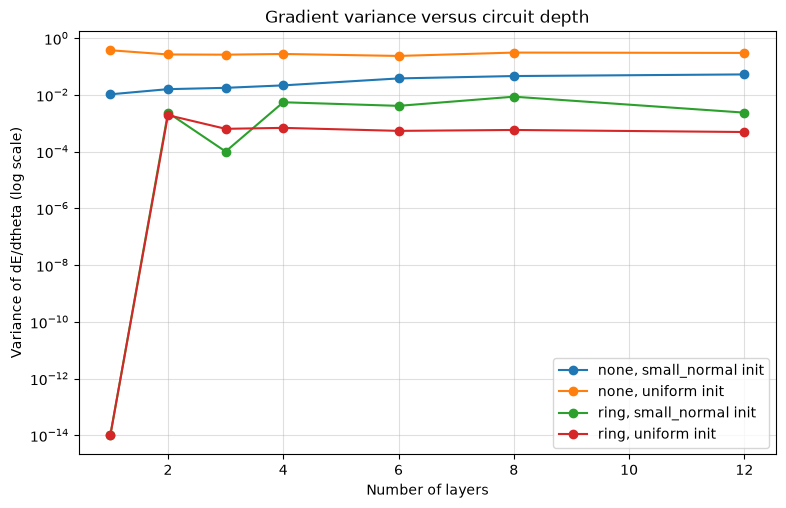

entanglement         none                    ring              
init         small_normal   uniform  small_normal       uniform
depth                                                          
1                0.010473  0.374681  3.455092e-17  4.092759e-17
2                0.015923  0.266141  2.362140e-03  1.930625e-03
3                0.017729  0.261632  1.007196e-04  6.364199e-04
4                0.021646  0.277083  5.497754e-03  6.873775e-04
6                0.038049  0.236063  4.104735e-03  5.389581e-04
8                0.046146  0.310070  8.641593e-03  5.798002e-04
12               0.052685  0.301515  2.369320e-03  4.912258e-04

In [11]:
# ============================================================
# CELL 12: Trainability - gradient variance versus depth
# ============================================================
#
# Deep random circuits can have exponentially vanishing gradients
# ("barren plateaus"). For each depth, the variance of the gradient of
# <Z_0> with respect to one parameter is estimated over random
# initialisations (uniform angles) and random inputs.
# A rapid decay with depth means very deep circuits will not train.

def gradient_variance(depth, entanglement, n_inits, init):

    grads = []

    for i in range(n_inits):

        torch.manual_seed(1000 + i)

        circuit = QuantumCircuitEmbedder(
            n_qubits=N_QUBITS, n_layers=depth, entanglement=entanglement,
            init=init, init_std=0.1, normalize_output=False
        )

        x = train_x[torch.randint(len(train_x), (32,))]

        circuit.expectations(x)[:, 0].mean().backward()

        grads.append(circuit.theta.grad[0, 0, 0].item())

    return float(np.var(grads))


rows = []

for entanglement in ["ring", "none"]:

    for init in ["uniform", "small_normal"]:

        for depth in tqdm(GRAD_DEPTHS, desc=f"{entanglement}/{init}",
                          leave=False):

            rows.append(
                {
                    "entanglement": entanglement,
                    "init": init,
                    "depth": depth,
                    "grad_variance": gradient_variance(
                        depth, entanglement, GRAD_INITS, init
                    )
                }
            )


grad_df = pd.DataFrame(rows)

grad_df.to_csv(OUTPUT_DIR / "gradient_variance.csv", index=False)


plt.figure(figsize=(9, 5.5))

for (entanglement, init), group in grad_df.groupby(["entanglement", "init"]):

    plt.semilogy(
        group["depth"], group["grad_variance"] + 1e-14, marker="o",
        label=f"{entanglement}, {init} init"
    )

plt.xlabel("Number of layers")

plt.ylabel("Variance of dE/dtheta (log scale)")

plt.title("Gradient variance versus circuit depth")

plt.legend()

plt.grid(True, which="both", alpha=0.4)

plt.show()

display(grad_df.pivot_table(
    index="depth", columns=["entanglement", "init"], values="grad_variance"
))

## Ablation sweeps

Starting from a default circuit, **one design factor at a time** is changed
and the circuit is trained on the cached embeddings (same seed, same
pairs). The default is:

| Factor | Default |
|---|---|
| Layers | 3 |
| Variational rotations | RY + RZ |
| Entanglement | ring, CNOT |
| Encoding | RY, once |
| Input scale | π |

Selection uses **validation AUC only**. A single seed is noisy (about
±0.003 AUC), so the sweep is a screening step: the best designs are
re-evaluated with several seeds afterwards.

In [12]:
# ============================================================
# CELL 14: Sweep definitions
# ============================================================

DEFAULT_CIRCUIT = dict(
    n_layers=3,
    rotations=("RY", "RZ"),
    entanglement="ring",
    entangler="CNOT",
    encoding=("RY",),
    reupload=False,
    input_scale=math.pi,
    trainable_input_scale=False
)


SWEEPS = {

    "depth": [dict(n_layers=l) for l in (1, 2, 3, 4, 6)],

    "rotations": [
        dict(rotations=("RY",)),
        dict(rotations=("RY", "RZ")),
        dict(rotations=("RX", "RY", "RZ")),
    ],

    "entanglement": [
        dict(entanglement="none"),
        dict(entanglement="linear"),
        dict(entanglement="ring"),
        dict(entanglement="all"),
        dict(entanglement="ring", entangler="CZ"),
    ],

    "encoding": [
        dict(encoding=("RY",)),
        dict(encoding=("RX",)),
        dict(encoding=("RY", "RZ")),
        dict(reupload=True),
    ],

    "input_scale": [
        dict(input_scale=1.0),
        dict(input_scale=math.pi / 2),
        dict(input_scale=math.pi),
        dict(input_scale=2 * math.pi),
        dict(trainable_input_scale=True),
    ],
}


def config_key(cfg):

    return json.dumps(cfg, sort_keys=True, default=list)


def config_label(cfg):

    changed = [
        f"{k}={v}" for k, v in cfg.items() if v != DEFAULT_CIRCUIT[k]
    ]

    return "default" if not changed else ", ".join(changed)


def build_circuit(cfg, seed):

    torch.manual_seed(seed)

    return QuantumCircuitEmbedder(n_qubits=N_QUBITS, **cfg)


jobs = {}

for factor, variations in SWEEPS.items():

    for variation in variations:

        cfg = {**DEFAULT_CIRCUIT, **variation}

        jobs.setdefault(config_key(cfg), (factor, cfg))


print("Distinct circuit designs to train:", len(jobs))

print(f"Epochs per design: {EPOCHS_SWEEP}   "
      f"(pairs/epoch {PAIRS_PER_EPOCH}, batch {BATCH_PAIRS})")

Distinct circuit designs to train: 18
Epochs per design: 15   (pairs/epoch 12800, batch 256)


In [13]:
# ============================================================
# CELL 15: Run the ablation sweeps
# ============================================================

sweep_rows = []

sweep_start = time.time()

for key, (factor, cfg) in tqdm(jobs.items(), desc="Sweeps"):

    t0 = time.time()

    module = build_circuit(cfg, SWEEP_SEED)

    module, best, _ = train_embedder(module, EPOCHS_SWEEP, SWEEP_SEED)

    sweep_rows.append(
        {
            "factor": factor,
            "design": config_label(cfg),
            "n_layers": cfg["n_layers"],
            "parameters": count_parameters(module),
            "best_epoch": best["epoch"],
            "val_auc": best["auc"],
            "val_eer": best["eer"],
            "val_accuracy": best["accuracy"],
            "seconds": round(time.time() - t0, 1),
            "config": key
        }
    )

    print(f"{config_label(cfg):60s} AUC {best['auc']:.4f}  "
          f"EER {best['eer']:.4f}  ({time.time() - t0:.0f}s)")


sweep_df = pd.DataFrame(sweep_rows)

sweep_df.to_csv(OUTPUT_DIR / "sweep_results.csv", index=False)

print(f"\nTotal sweep time: {(time.time() - sweep_start) / 60:.1f} min")

Sweeps:   0%|          | 0/18 [00:00<?, ?it/s]

n_layers=1                                                   AUC 0.8450  EER 0.2436  (69s)
n_layers=2                                                   AUC 0.8721  EER 0.2192  (88s)
default                                                      AUC 0.8740  EER 0.2156  (135s)
n_layers=4                                                   AUC 0.8764  EER 0.2126  (170s)
n_layers=6                                                   AUC 0.8808  EER 0.2068  (184s)
rotations=('RY',)                                            AUC 0.8728  EER 0.2174  (84s)
rotations=('RX', 'RY', 'RZ')                                 AUC 0.8779  EER 0.2078  (114s)
entanglement=none                                            AUC 0.8789  EER 0.2116  (97s)
entanglement=linear                                          AUC 0.8760  EER 0.2092  (146s)
entanglement=all                                             AUC 0.8726  EER 0.2172  (113s)
entangler=CZ                                                 AUC 0.8801  EER 0.2092 

,design,parameters,best_epoch,val_auc,val_eer,val_accuracy,seconds
0,input_scale=1.0,48,14,0.881869,0.2084,0.7956,110.4
1,input_scale=1.5707963267948966,48,9,0.881451,0.2068,0.8008,110.8
2,n_layers=6,96,9,0.880788,0.2068,0.7962,184.1
3,entangler=CZ,48,9,0.880077,0.2092,0.7962,135.2
4,entanglement=none,48,7,0.878893,0.2116,0.7922,96.5
5,trainable_input_scale=True,56,13,0.878692,0.2086,0.7980,129.7
6,"rotations=('RX', 'RY', 'RZ')",72,10,0.877890,0.2078,0.7948,113.6
7,n_layers=4,64,13,0.876393,0.2126,0.7952,169.8
8,entanglement=linear,48,15,0.875951,0.2092,0.7952,145.5
9,default,48,13,0.873981,0.2156,0.7896,135.1


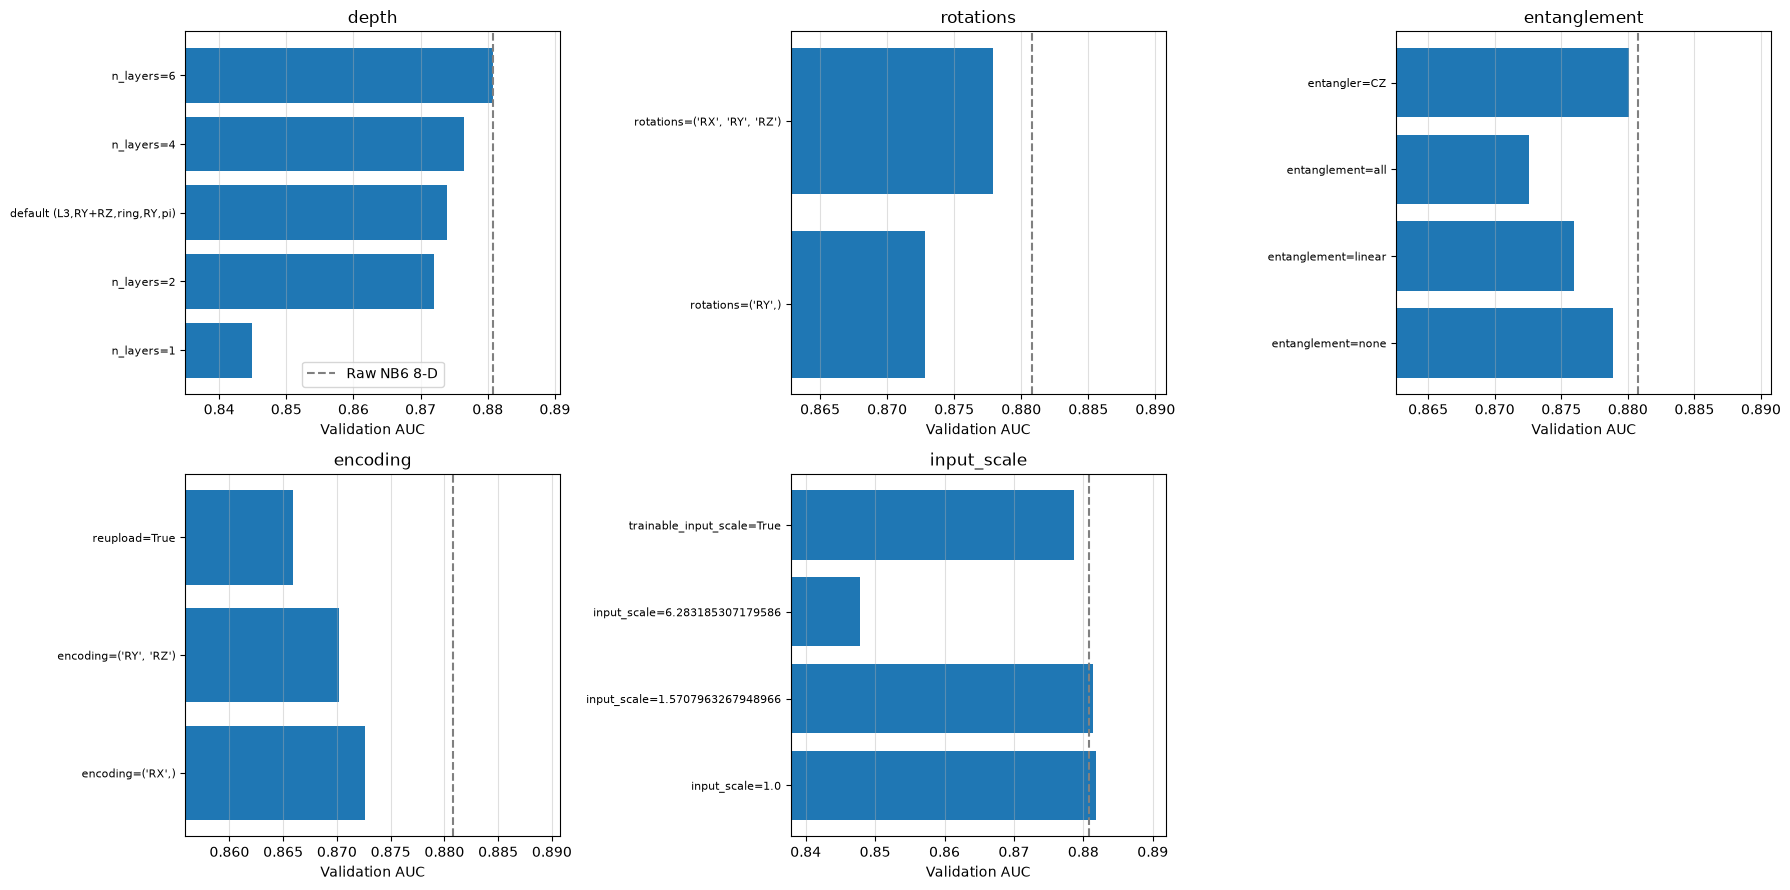

In [14]:
# ============================================================
# CELL 16: Sweep results
# ============================================================

display(
    sweep_df.sort_values("val_auc", ascending=False)[
        ["design", "parameters", "best_epoch", "val_auc", "val_eer",
         "val_accuracy", "seconds"]
    ].reset_index(drop=True)
)


factors = ["depth", "rotations", "entanglement", "encoding", "input_scale"]

fig, axes = plt.subplots(2, 3, figsize=(18, 9))

axes = axes.ravel()

for ax, factor in zip(axes, factors):

    group = sweep_df[sweep_df["factor"] == factor]

    labels = [d.replace("default", "default (L3,RY+RZ,ring,RY,pi)")
              for d in group["design"]]

    ax.barh(range(len(group)), group["val_auc"])

    ax.set_yticks(range(len(group)))

    ax.set_yticklabels(labels, fontsize=8)

    ax.axvline(raw_val["auc"], linestyle="--", color="gray",
               label="Raw NB6 8-D")

    lo = min(group["val_auc"].min(), raw_val["auc"]) - 0.01

    ax.set_xlim(lo, max(group["val_auc"].max(), raw_val["auc"]) + 0.01)

    ax.set_title(factor)

    ax.set_xlabel("Validation AUC")

    ax.grid(True, axis="x", alpha=0.4)

axes[0].legend()

axes[-1].axis("off")

plt.tight_layout()

plt.show()

In [15]:
# ============================================================
# CELL 17: Choose candidate designs
# ============================================================
#
# Candidates:
#   (a) the default circuit
#   (b) the best single design from the sweep
#   (c) a "combined" circuit: the best value of every factor together
#
# (c) was never trained as a whole, so it is trained now and compared
# like the others. All choices use VALIDATION AUC only.

def best_in_factor(factor):

    group = sweep_df[sweep_df["factor"] == factor]

    return json.loads(group.sort_values("val_auc").iloc[-1]["config"])


combined = dict(DEFAULT_CIRCUIT)

for factor, keys in {
    "depth": ["n_layers"],
    "rotations": ["rotations"],
    "entanglement": ["entanglement", "entangler"],
    "encoding": ["encoding", "reupload"],
    "input_scale": ["input_scale", "trainable_input_scale"],
}.items():

    winner = best_in_factor(factor)

    for k in keys:

        combined[k] = winner[k]


def normalise(cfg):

    cfg = dict(cfg)

    cfg["rotations"] = tuple(cfg["rotations"])

    cfg["encoding"] = tuple(cfg["encoding"])

    return cfg


combined = normalise(combined)

best_single = normalise(
    json.loads(sweep_df.sort_values("val_auc").iloc[-1]["config"])
)


candidates = {
    "default": normalise(DEFAULT_CIRCUIT),
    "best_single": best_single,
    "combined": combined,
}

# remove duplicates but keep names

unique = {}

for name, cfg in candidates.items():

    unique.setdefault(config_key(cfg), (name, cfg))


print("Candidate circuits:\n")

candidate_rows = []

for key, (name, cfg) in unique.items():

    module = build_circuit(cfg, SWEEP_SEED)

    module, best, _ = train_embedder(module, EPOCHS_FINAL, SWEEP_SEED)

    candidate_rows.append(
        {"name": name, "val_auc": best["auc"], "val_eer": best["eer"],
         "parameters": count_parameters(module), "config": cfg}
    )

    print(f"--- {name}: validation AUC {best['auc']:.4f}   "
          f"EER {best['eer']:.4f}")

    print(describe_circuit(cfg, N_QUBITS), "\n")


candidate_df = pd.DataFrame(candidate_rows)

winner = candidate_df.sort_values(
    ["val_auc", "parameters"], ascending=[False, True]
).iloc[0]

BEST_CIRCUIT = winner["config"]

print("=" * 70)

print("SELECTED CIRCUIT:", winner["name"],
      f"(validation AUC {winner['val_auc']:.4f})")

print("=" * 70)

print(describe_circuit(BEST_CIRCUIT, N_QUBITS))

Candidate circuits:

--- default: validation AUC 0.8753   EER 0.2160
Qubits        : 8
Encoding      : RY(scale * x_i) on qubit i   scale = 3.1416
Layers        : 3 x [ RY+RZ(theta) on every qubit -> CNOT ring ]
Entangling    : [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 6), (6, 7), (7, 0)]
Measurement   : <Z> on every qubit -> 8-D embedding
Trainable     : 48 parameters 

--- best_single: validation AUC 0.8823   EER 0.2068
Qubits        : 8
Encoding      : RY(scale * x_i) on qubit i   scale = 1.0000
Layers        : 3 x [ RY+RZ(theta) on every qubit -> CNOT ring ]
Entangling    : [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 6), (6, 7), (7, 0)]
Measurement   : <Z> on every qubit -> 8-D embedding
Trainable     : 48 parameters 

--- combined: validation AUC 0.8802   EER 0.2086
Qubits        : 8
Encoding      : RX(scale * x_i) on qubit i   scale = 1.0000
Layers        : 6 x [ RX+RY+RZ(theta) on every qubit -> CZ ring ]
Entangling    : [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 6), (6, 7

## Final comparison: quantum circuit versus classical heads

All models receive the **same cached 8-D embeddings**, the same training
pairs distribution, the same optimiser and the same validation-based model
selection, over several seeds:

| Model | Description | Parameters |
|---|---|---|
| Raw NB6 | Notebook 6 embedding, nothing added | 0 |
| Classical linear | 8×8 matrix (initialised at identity) + L2-norm | 64 |
| Classical MLP | 8→16→8 + L2-norm | 280 |
| **Quantum VQC** | selected circuit above | see table |

The classical heads are the fair control: any gain of the circuit should
exceed what a similarly sized classical layer provides.

In [16]:
# ============================================================
# CELL 19: Classical control heads
# ============================================================

class LinearHead(nn.Module):

    def __init__(self, dim=8):

        super().__init__()

        self.linear = nn.Linear(dim, dim, bias=False)

        with torch.no_grad():

            self.linear.weight.copy_(
                torch.eye(dim) + 0.01 * torch.randn(dim, dim)
            )

    def forward(self, x):

        return F.normalize(self.linear(x), p=2, dim=1, eps=1e-6)


class MLPHead(nn.Module):

    def __init__(self, dim=8, hidden=16):

        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(dim, hidden),
            nn.GELU(),
            nn.Linear(hidden, dim)
        )

    def forward(self, x):

        return F.normalize(self.net(x) + x, p=2, dim=1, eps=1e-6)   # residual


print("LinearHead parameters:", count_parameters(LinearHead()))

print("MLPHead parameters   :", count_parameters(MLPHead()))

LinearHead parameters: 64
MLPHead parameters   : 280


In [17]:
# ============================================================
# CELL 20: Multi-seed final runs
# ============================================================

def make_model(kind, seed):

    torch.manual_seed(seed)

    if kind == "Classical linear":

        return LinearHead()

    if kind == "Classical MLP":

        return MLPHead()

    return build_circuit(BEST_CIRCUIT, seed)


model_kinds = ["Classical linear", "Classical MLP", "Quantum VQC"]

final_rows = []

trained_models = {}

curves = {}

for kind in model_kinds:

    for seed in FINAL_SEEDS:

        module = make_model(kind, seed)

        module, best, history = train_embedder(module, EPOCHS_FINAL, seed)

        test_result = evaluate_on_test(module, best["threshold"])

        final_rows.append(
            {
                "model": kind,
                "seed": seed,
                "parameters": count_parameters(module),
                "best_epoch": best["epoch"],
                "val_auc": best["auc"],
                "val_eer": best["eer"],
                "val_accuracy": best["accuracy"],
                "threshold": best["threshold"],
                "test_accuracy": test_result["test_accuracy"],
                "test_auc": test_result["test_auc"],
                "test_eer": test_result["test_eer"],
                "test_far": test_result["test_far"],
                "test_frr": test_result["test_frr"],
            }
        )

        trained_models[(kind, seed)] = module

        curves[(kind, seed)] = test_result

        print(f"{kind:17s} seed {seed}  val AUC {best['auc']:.4f}  "
              f"test AUC {test_result['test_auc']:.4f}  "
              f"test EER {test_result['test_eer']:.4f}")


# Raw baseline (deterministic, one row)

final_rows.append(
    {
        "model": "Raw NB6 8-D",
        "seed": -1,
        "parameters": 0,
        "best_epoch": 0,
        "val_auc": raw_val["auc"],
        "val_eer": raw_val["eer"],
        "val_accuracy": raw_val["accuracy"],
        "threshold": raw_val["threshold"],
        "test_accuracy": raw_test["test_accuracy"],
        "test_auc": raw_test["test_auc"],
        "test_eer": raw_test["test_eer"],
        "test_far": raw_test["test_far"],
        "test_frr": raw_test["test_frr"],
    }
)

final_df = pd.DataFrame(final_rows)

final_df.to_csv(OUTPUT_DIR / "final_runs_all_seeds.csv", index=False)

Classical linear  seed 0  val AUC 0.8833  test AUC 0.8768  test EER 0.2166
Classical linear  seed 1  val AUC 0.8831  test AUC 0.8765  test EER 0.2162
Classical linear  seed 2  val AUC 0.8823  test AUC 0.8763  test EER 0.2172
Classical MLP     seed 0  val AUC 0.8834  test AUC 0.8776  test EER 0.2158
Classical MLP     seed 1  val AUC 0.8833  test AUC 0.8764  test EER 0.2180
Classical MLP     seed 2  val AUC 0.8826  test AUC 0.8767  test EER 0.2166
Quantum VQC       seed 0  val AUC 0.8823  test AUC 0.8759  test EER 0.2182
Quantum VQC       seed 1  val AUC 0.8804  test AUC 0.8752  test EER 0.2172
Quantum VQC       seed 2  val AUC 0.8798  test AUC 0.8756  test EER 0.2188


In [18]:
# ============================================================
# CELL 21: Summary table (mean ± std over seeds)
# ============================================================

metric_columns = ["val_auc", "test_accuracy", "test_auc", "test_eer",
                  "test_far", "test_frr"]

summary = (
    final_df.groupby("model")
    .agg(
        parameters=("parameters", "first"),
        seeds=("seed", "count"),
        **{f"{m}_mean": (m, "mean") for m in metric_columns},
        **{f"{m}_std": (m, "std") for m in metric_columns},
    )
    .reset_index()
)

order = ["Raw NB6 8-D", "Classical linear", "Classical MLP", "Quantum VQC"]

summary["model"] = pd.Categorical(summary["model"], order, ordered=True)

summary = summary.sort_values("model").reset_index(drop=True)

summary.to_csv(OUTPUT_DIR / "final_comparison.csv", index=False)


def fmt(row, metric):

    std = row[f"{metric}_std"]

    return (f"{row[f'{metric}_mean']:.4f}"
            + (f" ± {std:.4f}" if pd.notna(std) else ""))


pretty = pd.DataFrame(
    {
        "Model": summary["model"],
        "Params": summary["parameters"],
        "Seeds": summary["seeds"],
        "Val AUC": [fmt(r, "val_auc") for _, r in summary.iterrows()],
        "Test Acc": [fmt(r, "test_accuracy") for _, r in summary.iterrows()],
        "Test AUC": [fmt(r, "test_auc") for _, r in summary.iterrows()],
        "Test EER": [fmt(r, "test_eer") for _, r in summary.iterrows()],
        "Test FAR": [fmt(r, "test_far") for _, r in summary.iterrows()],
        "Test FRR": [fmt(r, "test_frr") for _, r in summary.iterrows()],
    }
)

display(pretty)


quantum = final_df[final_df["model"] == "Quantum VQC"]["test_auc"]

for other in ["Raw NB6 8-D", "Classical linear", "Classical MLP"]:

    other_auc = final_df[final_df["model"] == other]["test_auc"].mean()

    print(f"Quantum VQC test AUC minus {other:17s}: "
          f"{quantum.mean() - other_auc:+.4f}   "
          f"(seed std of quantum = {quantum.std():.4f})")

,Model,Params,Seeds,Val AUC,Test Acc,Test AUC,Test EER,Test FAR,Test FRR
0,Raw NB6 8-D,0,1,0.8808,0.7858,0.8747,0.2218,0.2516,0.1768
1,Classical linear,64,3,0.8829 ± 0.0005,0.7899 ± 0.0019,0.8765 ± 0.0003,0.2167 ± 0.0005,0.2464 ± 0.0087,0.1739 ± 0.0125
2,Classical MLP,280,3,0.8831 ± 0.0004,0.7912 ± 0.0009,0.8769 ± 0.0006,0.2168 ± 0.0011,0.2667 ± 0.0163,0.1509 ± 0.0162
3,Quantum VQC,48,3,0.8808 ± 0.0013,0.7868 ± 0.0039,0.8755 ± 0.0003,0.2181 ± 0.0008,0.2635 ± 0.0206,0.1629 ± 0.0275


Quantum VQC test AUC minus Raw NB6 8-D      : +0.0008   (seed std of quantum = 0.0003)
Quantum VQC test AUC minus Classical linear : -0.0010   (seed std of quantum = 0.0003)
Quantum VQC test AUC minus Classical MLP    : -0.0014   (seed std of quantum = 0.0003)


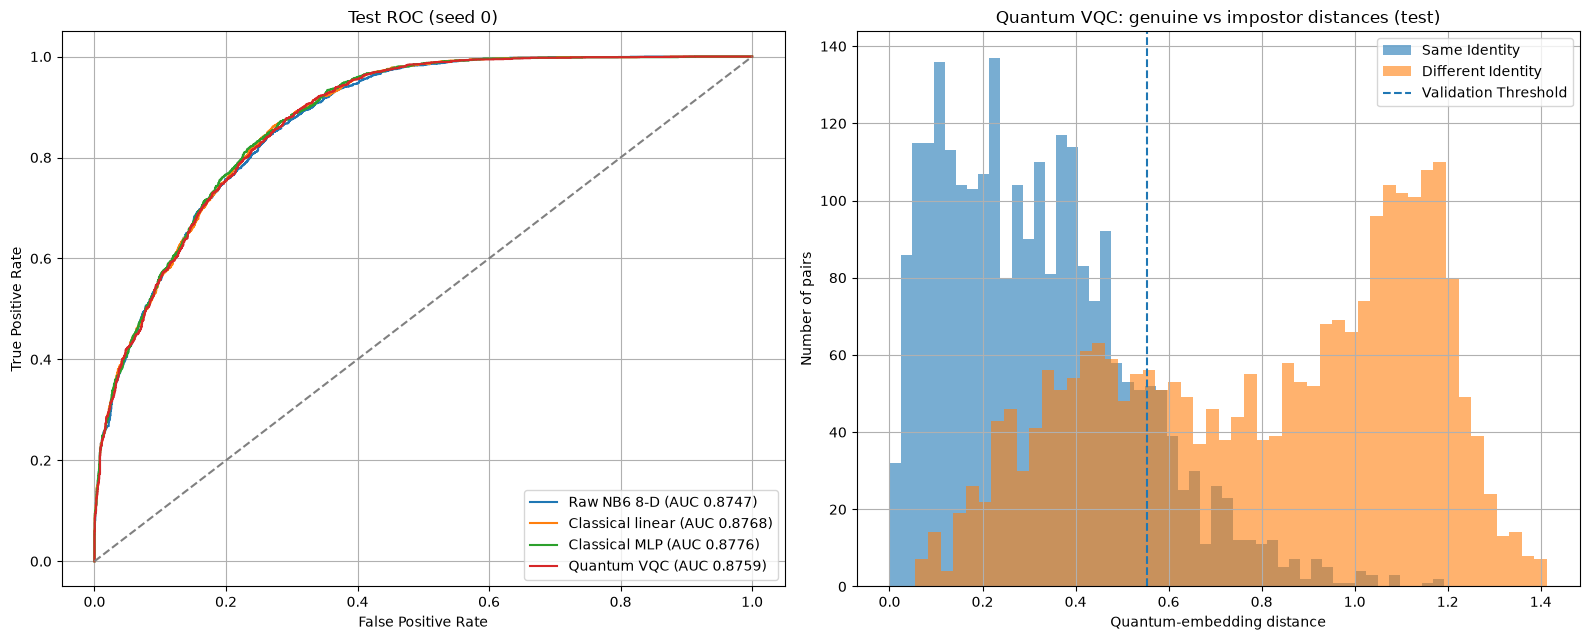

In [19]:
# ============================================================
# CELL 22: ROC curves and distance distributions
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

plot_seed = FINAL_SEEDS[0]

axes[0].plot(raw_test["fpr"], raw_test["tpr"],
             label=f"Raw NB6 8-D (AUC {raw_test['test_auc']:.4f})")

for kind in model_kinds:

    result = curves[(kind, plot_seed)]

    axes[0].plot(result["fpr"], result["tpr"],
                 label=f"{kind} (AUC {result['test_auc']:.4f})")

axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")

axes[0].set_xlabel("False Positive Rate")

axes[0].set_ylabel("True Positive Rate")

axes[0].set_title(f"Test ROC (seed {plot_seed})")

axes[0].legend()

axes[0].grid(True)


quantum_result = curves[("Quantum VQC", plot_seed)]

genuine = quantum_result["distances"][test_pairs["y"] == 0]

impostor = quantum_result["distances"][test_pairs["y"] == 1]

threshold = final_df[
    (final_df["model"] == "Quantum VQC") & (final_df["seed"] == plot_seed)
]["threshold"].iloc[0]

axes[1].hist(genuine, bins=50, alpha=0.6, label="Same Identity")

axes[1].hist(impostor, bins=50, alpha=0.6, label="Different Identity")

axes[1].axvline(threshold, linestyle="--", label="Validation Threshold")

axes[1].set_xlabel("Quantum-embedding distance")

axes[1].set_ylabel("Number of pairs")

axes[1].set_title("Quantum VQC: genuine vs impostor distances (test)")

axes[1].legend()

axes[1].grid(True)

plt.tight_layout()

plt.show()

Circuit parameter tensor shape (layers, qubits, rotations): (3, 8, 2)
Rotation-angle statistics (radians):
  mean |theta| = 0.437   max |theta| = 1.109
  input scale: [1. 1. 1. 1. 1. 1. 1. 1.]


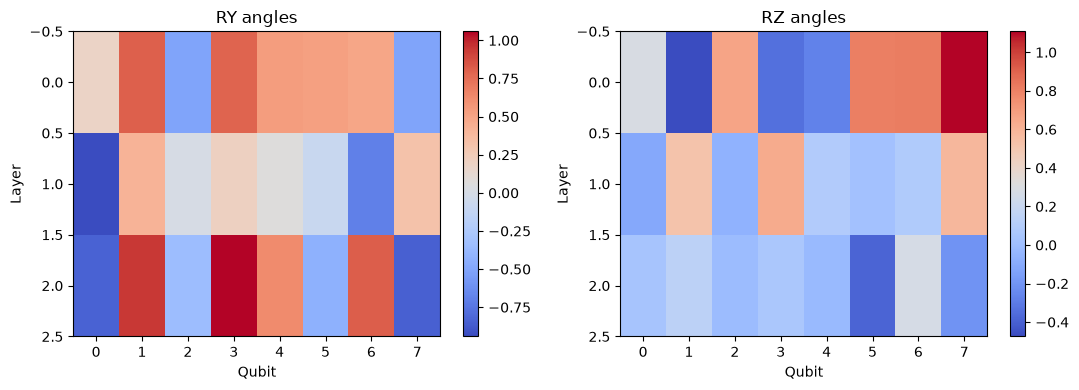

In [20]:
# ============================================================
# CELL 23: Learned input scale and rotation angles (inspection)
# ============================================================

best_quantum = trained_models[("Quantum VQC", FINAL_SEEDS[0])]

theta = best_quantum.theta.detach().cpu().numpy()

print("Circuit parameter tensor shape (layers, qubits, rotations):",
      theta.shape)

print("Rotation-angle statistics (radians):")

print(f"  mean |theta| = {np.abs(theta).mean():.3f}   "
      f"max |theta| = {np.abs(theta).max():.3f}")

print("  input scale:", np.round(best_quantum.input_scale.detach().cpu().numpy(), 3))


fig, axes = plt.subplots(
    1, theta.shape[2], figsize=(5.5 * theta.shape[2], 4), squeeze=False
)

for k, name in enumerate(best_quantum.rotations):

    image = axes[0, k].imshow(
        theta[:, :, k], aspect="auto", cmap="coolwarm"
    )

    axes[0, k].set_title(f"{name} angles")

    axes[0, k].set_xlabel("Qubit")

    axes[0, k].set_ylabel("Layer")

    plt.colorbar(image, ax=axes[0, k])

plt.tight_layout()

plt.show()

In [21]:
# ============================================================
# CELL 24: Save circuit configuration, weights and results
# ============================================================

config_to_save = {
    "n_qubits": N_QUBITS,
    **{k: (list(v) if isinstance(v, tuple) else v)
       for k, v in BEST_CIRCUIT.items()},
    "normalize_output": True,
    "init": "small_normal",
    "init_std": 0.1,
    "learning_rate": LEARNING_RATE,
    "contrastive_margin": CONTRASTIVE_MARGIN
}

with open(OUTPUT_DIR / "best_circuit_config.json", "w") as file:

    json.dump(config_to_save, file, indent=2)


for seed in FINAL_SEEDS:

    module = trained_models[("Quantum VQC", seed)]

    torch.save(
        {
            "state_dict": module.state_dict(),
            "circuit_config": config_to_save,
            "seed": seed
        },
        OUTPUT_DIR / f"best_quantum_circuit_seed{seed}.pth"
    )


quantum_rows = final_df[final_df["model"] == "Quantum VQC"]

best_row = quantum_rows.sort_values("val_auc", ascending=False).iloc[0]

pd.DataFrame([best_row]).to_csv(OUTPUT_DIR / "final_results.csv", index=False)

pd.DataFrame(
    [
        {
            "seed": SEED,
            "sweep_seed": SWEEP_SEED,
            "final_seeds": str(FINAL_SEEDS),
            "learning_rate": LEARNING_RATE,
            "batch_pairs": BATCH_PAIRS,
            "pairs_per_epoch": PAIRS_PER_EPOCH,
            "epochs_sweep": EPOCHS_SWEEP,
            "epochs_final": EPOCHS_FINAL,
            "patience": PATIENCE,
            "contrastive_margin": CONTRASTIVE_MARGIN,
            "n_qubits": N_QUBITS,
            "quick_test": QUICK_TEST
        }
    ]
).to_csv(OUTPUT_DIR / "experiment_configuration.csv", index=False)


print("Saved to:", OUTPUT_DIR)

for path in sorted(OUTPUT_DIR.iterdir()):

    print(" -", path.name)

Saved to: ..\quantum_circuit_experiments
 - __pycache__
 - best_circuit_config.json
 - best_quantum_circuit_seed0.pth
 - best_quantum_circuit_seed1.pth
 - best_quantum_circuit_seed2.pth
 - experiment_configuration.csv
 - final_comparison.csv
 - final_results.csv
 - final_runs_all_seeds.csv
 - gradient_variance.csv
 - quantum_sim.py
 - sweep_results.csv


In [22]:
# ============================================================
# CELL 25: Final Summary
# ============================================================

print("=" * 70)

print("NOTEBOOK 7 COMPLETED SUCCESSFULLY")

print("=" * 70)

print("\nSELECTED QUANTUM CIRCUIT\n")

print(describe_circuit(BEST_CIRCUIT, N_QUBITS))

print("\nTEST RESULTS (mean over seeds)\n")

display(pretty)

print("\nNotebook 6 reference (classical 128 -> 8 projection, test):")

print(f"  AUC {nb6['test_auc']:.4f}   EER {nb6['test_eer']:.4f}   "
      f"Acc {nb6['test_accuracy']:.4f}")

print("\nCircuit configuration for Notebook 8:")

print(OUTPUT_DIR / "best_circuit_config.json")

print("\n✓ Notebook 7 is complete.")

NOTEBOOK 7 COMPLETED SUCCESSFULLY

SELECTED QUANTUM CIRCUIT

Qubits        : 8
Encoding      : RY(scale * x_i) on qubit i   scale = 1.0000
Layers        : 3 x [ RY+RZ(theta) on every qubit -> CNOT ring ]
Entangling    : [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 6), (6, 7), (7, 0)]
Measurement   : <Z> on every qubit -> 8-D embedding
Trainable     : 48 parameters

TEST RESULTS (mean over seeds)



,Model,Params,Seeds,Val AUC,Test Acc,Test AUC,Test EER,Test FAR,Test FRR
0,Raw NB6 8-D,0,1,0.8808,0.7858,0.8747,0.2218,0.2516,0.1768
1,Classical linear,64,3,0.8829 ± 0.0005,0.7899 ± 0.0019,0.8765 ± 0.0003,0.2167 ± 0.0005,0.2464 ± 0.0087,0.1739 ± 0.0125
2,Classical MLP,280,3,0.8831 ± 0.0004,0.7912 ± 0.0009,0.8769 ± 0.0006,0.2168 ± 0.0011,0.2667 ± 0.0163,0.1509 ± 0.0162
3,Quantum VQC,48,3,0.8808 ± 0.0013,0.7868 ± 0.0039,0.8755 ± 0.0003,0.2181 ± 0.0008,0.2635 ± 0.0206,0.1629 ± 0.0275



Notebook 6 reference (classical 128 -> 8 projection, test):
  AUC 0.8747   EER 0.2218   Acc 0.7858

Circuit configuration for Notebook 8:
..\quantum_circuit_experiments\best_circuit_config.json

✓ Notebook 7 is complete.


## How to read the results

- **A quantum circuit that only matches the classical heads is still a valid
  finding.** On 8-D inputs a classical 64-parameter head and a 48-parameter
  circuit can be equally good; the interesting questions are then parameter
  count, trainability and robustness, not accuracy.
- Compare differences against the **seed standard deviation**. If the gap
  between the quantum model and a classical head is smaller than that, report
  it as "no significant difference".
- The `entanglement = none` row of the sweep is the key ablation: if it is as
  good as the entangled circuits, entanglement is not what the circuit is
  contributing on this task.
- The gradient-variance plot explains **why** very deep circuits are not
  used (trainability), independent of validation scores.

## Notes for Notebook 8 (end-to-end hybrid model)

```python
import sys, json
sys.path.insert(0, "../quantum_circuit_experiments")
from quantum_sim import QuantumCircuitEmbedder

config = json.load(open("../quantum_circuit_experiments/best_circuit_config.json"))
config.pop("learning_rate")
config.pop("contrastive_margin")
quantum_head = QuantumCircuitEmbedder(**config)
```

- Feed it the **L2-normalised 8-D** output of the Notebook 6 projection head:
  the circuit was designed on exactly this input range.
- Initialise the CNN encoder from Notebook 5/6 and train the projection head
  and circuit together with the contrastive loss; use the same validation and
  test pairs.
- Compare against `../classical_projection_baseline/final_results.csv`
  (test AUC 0.8747, EER 0.2218) and against the multi-seed table above.